# **PART C — Multiple Linear Regression and Feature Scaling:**

## **Problem**

## **C1. Multiple-feature cost function:**
Implement the cost function for \(m\) examples and \(n\) features.
$$
J(\vec w,b)=
\frac{1}{2m}
\sum_{i=1}^{m}
(f_{\vec w,b}(\vec x^{(i)})-y^{(i)})^2
$$

You must use a loop over training examples.

Also implement the gradient calculation for all feature weights.

Make sure the gradient for each feature has the correct shape.

## **C2. Feature scaling:**
Implement all three methods without using Scikit-learn:

1. Dividing by maximum
$$
x_{\text{scaled}}=\frac{x}{x_{\max}}
$$

2. Mean normalization
$$
x_{\text{norm}}=
\frac{x-\mu}{x_{\max}-x_{\min}}
$$

3. Z-score normalization
$$
x_{\text{z-score}}=
\frac{x-\mu}{\sigma}
$$

Requirements:
- Apply all three transformations to X_train.
- Print the resulting arrays.
- Print the minimum and maximum for each transformed feature.
- Compare the numerical ranges.
- Plot the original and normalized feature distributions.
Important: Fit the scaling statistics on training data only. Reuse those statistics when transforming test data.

## **C3. Experiment:**
Train the same multiple linear regression model:
- Once using original features.
- Once using Z-score-normalized features.
Use the same starting parameters and a suitable learning rate for each experiment.

Compare:
- Final cost.
- Number of iterations needed.
- Training convergence plots.
Explain why feature scaling can make gradient descent more efficient.

## **Dataset:**

Use this dataset:
```python
X_train = np.array([    
    [952, 2, 1, 65],    
    [1244, 3, 2, 64],    
    [1947, 3, 2, 17],    
    [1000, 2, 1, 40],
    [1500, 3, 1, 25],    
    [1800, 4, 2, 15],    
    [2200, 4, 2, 10],    
    [2500, 5, 2, 5]])

    y_train = np.array([271.5, 232, 509.8, 310, 390, 470, 530, 610])
```


Features:
1. House size.
2. Number of bedrooms.
3. Number of floors.
4. Age of the house.
Target: Price in thousands of dollars.

## **Solution:**

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.preprocessing import StandardScaler, MinMaxScaler

X_train = np.array([    
    [952, 2, 1, 65],    
    [1244, 3, 2, 64],    
    [1947, 3, 2, 17],    
    [1000, 2, 1, 40],
    [1500, 3, 1, 25],    
    [1800, 4, 2, 15],    
    [2200, 4, 2, 10],    
    [2500, 5, 2, 5]])

y_train = np.array([271.5, 232, 509.8, 310, 390, 470, 530, 610])

### C1  

In [10]:
def compute_cost(x, y, w, b):

    m = x.shape[0]

    cost_sum = 0

    for i in range(m):
        f_wb = np.dot(x[i], w) + b

        cost = (f_wb - y[i]) ** 2
        cost_sum += cost

    return (1 / (2 * m)) * cost_sum

In [8]:
def compute_gradient(x, y, w, b):

    m, n = x.shape
    dj_dw = np.zeros((n,))
    dj_db = 0

    for i in range(m):
        f_wb = np.dot(x[i], w) + b 
        err = f_wb - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + (err * x[i,j])

        dj_db = dj_db + err  

    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

In [13]:
w_test = np.array([1.0, 2.0, 1.5, 0.5])
b_test = 0.0

cost = compute_cost(X_train, y_train, w_test, b_test)
dj_dw, dj_db = compute_gradient(X_train, y_train, w_test, b_test)

print("Cost:", cost)
print("dj_dw shape:", dj_dw.shape)
print("dj_dw:", dj_dw)
print("dj_db:", dj_db)

Cost: 863876.380625
dj_dw shape: (4,)
dj_dw: [2.26712436e+06 4.43082500e+03 2.18242500e+03 3.02886750e+04]
dj_db: 1251.4625


### C2

In [19]:
X_train

array([[ 952,    2,    1,   65],
       [1244,    3,    2,   64],
       [1947,    3,    2,   17],
       [1000,    2,    1,   40],
       [1500,    3,    1,   25],
       [1800,    4,    2,   15],
       [2200,    4,    2,   10],
       [2500,    5,    2,    5]])

In [22]:
np.set_printoptions(precision=2, suppress=True)

mu = np.mean(X_train, axis=0)
sigma = np.std(X_train, axis=0)
x_min = np.min(X_train, axis=0)
x_max = np.max(X_train, axis=0)

X_max_scaled = X_train / x_max
X_mean_norm = (X_train - mu) / (x_max - x_min)
X_zscore = (X_train - mu) / sigma

def inspect_scaled_data(name, X_data):
    print(f"=== {name} ===")
    print(X_data)
    print("Min per feature:", np.min(X_data, axis=0))
    print("Max per feature:", np.max(X_data, axis=0))
    print()

inspect_scaled_data("Original X_train", X_train)
inspect_scaled_data("1. Dividing by Maximum", X_max_scaled)
inspect_scaled_data("2. Mean Normalization", X_mean_norm)
inspect_scaled_data("3. Z-score Normalization", X_zscore)


=== Original X_train ===
[[ 952    2    1   65]
 [1244    3    2   64]
 [1947    3    2   17]
 [1000    2    1   40]
 [1500    3    1   25]
 [1800    4    2   15]
 [2200    4    2   10]
 [2500    5    2    5]]
Min per feature: [952   2   1   5]
Max per feature: [2500    5    2   65]

=== 1. Dividing by Maximum ===
[[0.38 0.4  0.5  1.  ]
 [0.5  0.6  1.   0.98]
 [0.78 0.6  1.   0.26]
 [0.4  0.4  0.5  0.62]
 [0.6  0.6  0.5  0.38]
 [0.72 0.8  1.   0.23]
 [0.88 0.8  1.   0.15]
 [1.   1.   1.   0.08]]
Min per feature: [0.38 0.4  0.5  0.08]
Max per feature: [1. 1. 1. 1.]

=== 2. Mean Normalization ===
[[-0.45 -0.42 -0.62  0.58]
 [-0.26 -0.08  0.38  0.56]
 [ 0.2  -0.08  0.38 -0.22]
 [-0.42 -0.42 -0.62  0.16]
 [-0.09 -0.08 -0.62 -0.09]
 [ 0.1   0.25  0.38 -0.25]
 [ 0.36  0.25  0.38 -0.34]
 [ 0.55  0.58  0.38 -0.42]]
Min per feature: [-0.45 -0.42 -0.62 -0.42]
Max per feature: [0.55 0.58 0.38 0.58]

=== 3. Z-score Normalization ===
[[-1.31 -1.29 -1.29  1.57]
 [-0.76 -0.26  0.77  1.53]
 [ 0.58 -0.

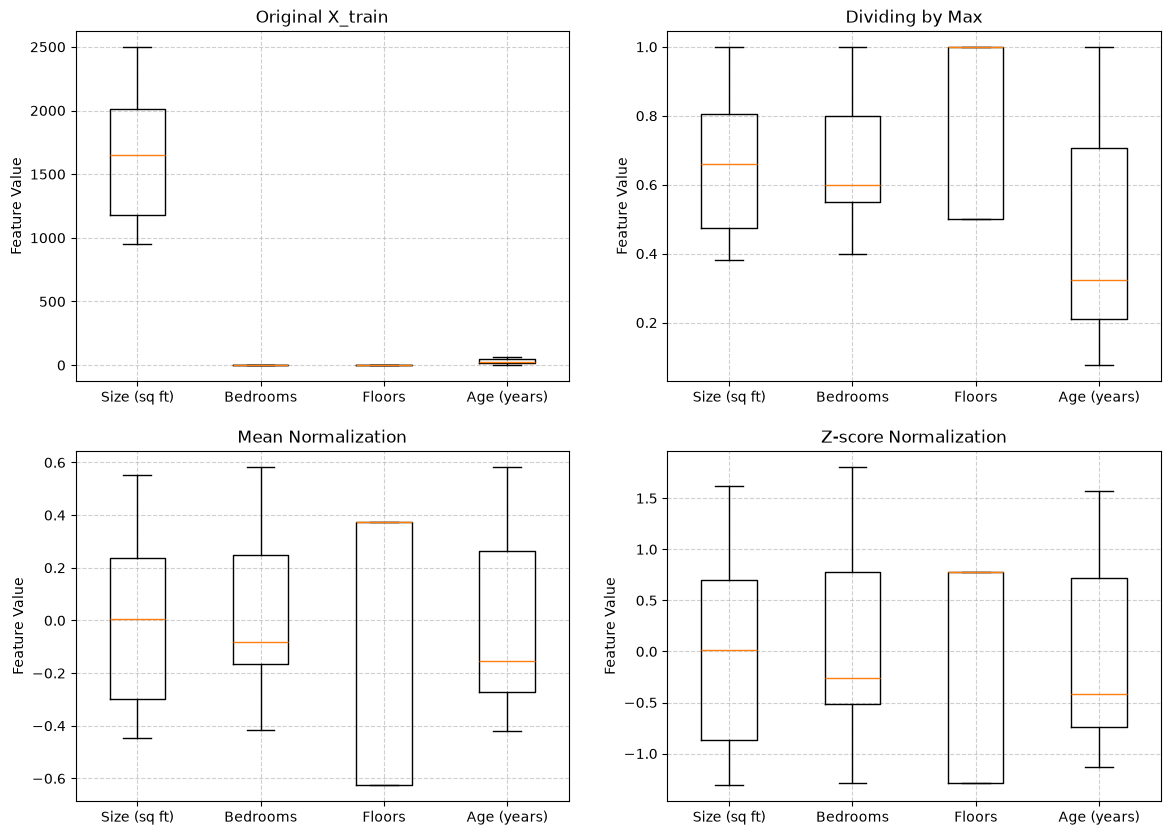

In [23]:
feature_names = ["Size (sq ft)", "Bedrooms", "Floors", "Age (years)"]
datasets = [
    ("Original X_train", X_train),
    ("Dividing by Max", X_max_scaled),
    ("Mean Normalization", X_mean_norm),
    ("Z-score Normalization", X_zscore)
]

fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.flatten()

for i, (title, data) in enumerate(datasets):
    axes[i].boxplot(data, tick_labels=feature_names)
    axes[i].set_title(title)
    axes[i].set_ylabel("Feature Value")
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.show()

### C3

In [ ]:
def gradient_descent_multi(x, y, w_in, b_in, alpha, iterations):
    J_history = []
    w = w_in.copy()
    b = b_in

    for i in range(iterations):
        cost = compute_cost(x, y, w, b)
        dj_dw, dj_db = compute_gradient(x, y, w, b)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        J_history.append(cost)
    return w, b, J_history

# 2. Prepare Z-score normalized features (fit on X_train only)
mu = np.mean(X_train, axis=0)
sigma = np.std(X_train, axis=0)
X_zscore = (X_train - mu) / sigma

# Same starting parameters for both experiments
n_features = X_train.shape[1]
w_init = np.zeros(n_features)
b_init = 0.0
iterations = 1000

# Experiment A: Train on ORIGINAL features (requires a tiny learning rate)
alpha_orig = 1e-7
w_orig, b_orig, cost_orig = gradient_descent_multi(
    X_train, y_train, w_init, b_init, alpha_orig, iterations
)

# Experiment B: Train on Z-SCORE NORMALIZED features (allows a much larger learning rate)
alpha_norm = 0.1
w_norm, b_norm, cost_norm = gradient_descent_multi(
    X_zscore, y_train, w_init, b_init, alpha_norm, iterations
)

# Print comparison metrics
print("=== Comparison After 1,000 Iterations ===")
print(f"Original Features   (alpha={alpha_orig}) -> Final Cost: {cost_orig[-1]:.4f}")
print(f"Normalized Features (alpha={alpha_norm})  -> Final Cost: {cost_norm[-1]:.4f}")


=== Comparison After 1,000 Iterations ===
Original Features   (alpha=1e-07) -> Final Cost: 795.8497
Normalized Features (alpha=0.1)  -> Final Cost: 190.1340


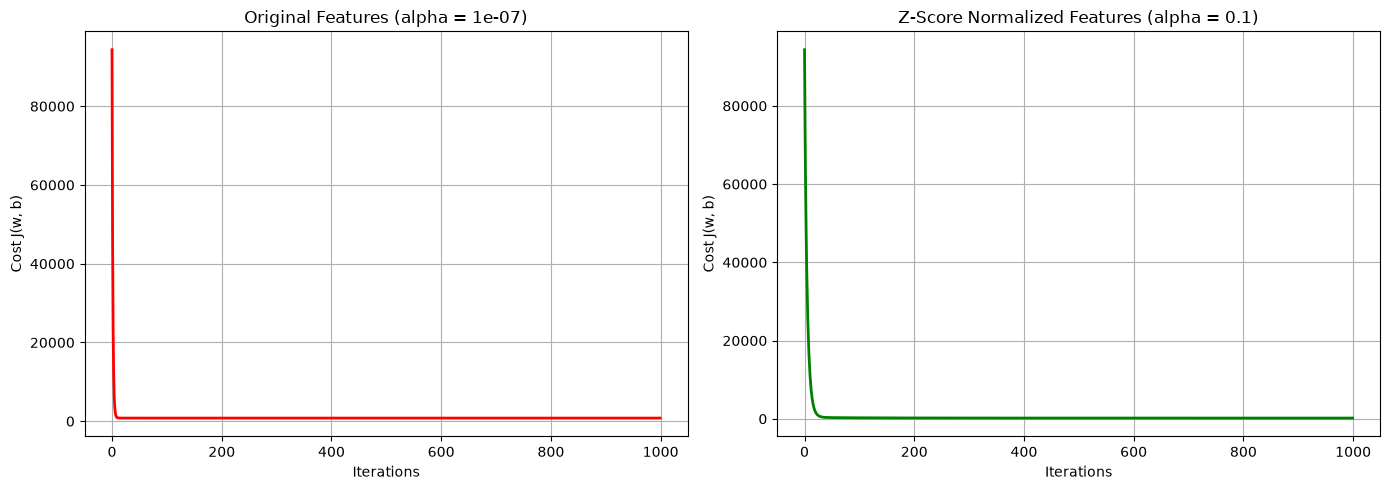

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Original features convergence
axs[0].plot(range(iterations), cost_orig, color='red', linewidth=2)
axs[0].set_title(f"Original Features (alpha = {alpha_orig})")
axs[0].set_xlabel("Iterations")
axs[0].set_ylabel("Cost J(w, b)")
axs[0].grid(True)

# Plot 2: Z-score normalized features convergence
axs[1].plot(range(iterations), cost_norm, color='green', linewidth=2)
axs[1].set_title(f"Z-Score Normalized Features (alpha = {alpha_norm})")
axs[1].set_xlabel("Iterations")
axs[1].set_ylabel("Cost J(w, b)")
axs[1].grid(True)

plt.tight_layout()
plt.show()
